In [1]:
%pip install opencv-python numpy matplotlib

  Using cached opencv_python-5.0.0.93-cp37-abi3-win_amd64.whl.metadata (20 kB)
Using cached opencv_python-5.0.0.93-cp37-abi3-win_amd64.whl (44.0 MB)
Note: you may need to restart the kernel to use updated packages.


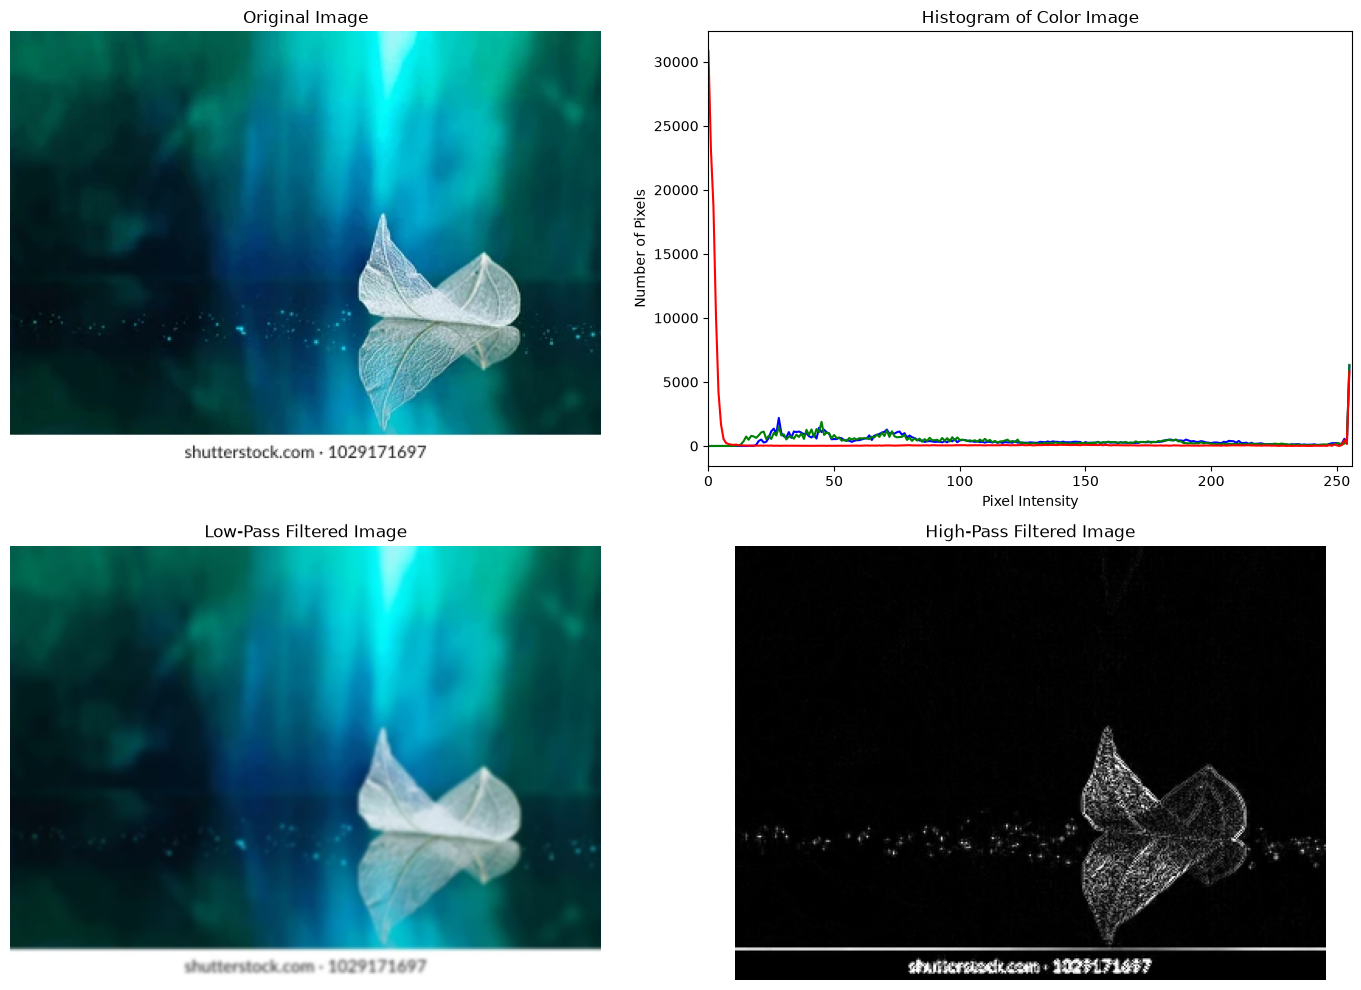

In [ ]:
#lab-1:Display following image operation in MATLAB/Python - i) Histogram  image  ii) Low pass filter mage  iii) High pass image.

import cv2
import matplotlib.pyplot as plt
import os

# Read original color image
path = r"C:\Users\nitud\Downloads\image.jpg.webp"

if not os.path.exists(path):
    print("Image file not found. Check the image path!")
    raise SystemExit

img = cv2.imread(path)

if img is None:
    print("Unable to read image!")
    raise SystemExit

# Convert BGR to RGB
original_img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

# i) Histogram of Color Image
plt.figure(figsize=(14, 10))

plt.subplot(2, 2, 1)
plt.imshow(original_img)
plt.title("Original Image")
plt.axis("off")

plt.subplot(2, 2, 2)

colors = ('b', 'g', 'r')

for i, color in enumerate(colors):
    histogram = cv2.calcHist(
        [img], [i], None, [256], [0, 256]
    )
    plt.plot(histogram, color=color)

plt.title("Histogram of Color Image")
plt.xlabel("Pixel Intensity")
plt.ylabel("Number of Pixels")
plt.xlim([0, 256])

# ii) Low-Pass Filter
low_pass = cv2.GaussianBlur(original_img, (5, 5), 0)

plt.subplot(2, 2, 3)
plt.imshow(low_pass)
plt.title("Low-Pass Filtered Image")
plt.axis("off")

# iii) High-Pass Filter
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

high_pass = cv2.Laplacian(gray, cv2.CV_64F)
high_pass = cv2.convertScaleAbs(high_pass)

plt.subplot(2, 2, 4)
plt.imshow(high_pass, cmap="gray")
plt.title("High-Pass Filtered Image")
plt.axis("off")

plt.tight_layout()
plt.show()


In [12]:
%pip install opencv-python scikit-image matplotlib numpy

  Using cached scikit_image-0.26.0-cp314-cp314-win_amd64.whl.metadata (15 kB)
Using cached scikit_image-0.26.0-cp314-cp314-win_amd64.whl (12.0 MB)

   ---------------------------------------- 0/3 [tifffile]
   ---------------------------------------- 0/3 [tifffile]
   ---------------------------------------- 0/3 [tifffile]
   ---------------------------------------- 0/3 [tifffile]
   ---------------------------------------- 0/3 [tifffile]
   ---------------------------------------- 0/3 [tifffile]
   ---------------------------------------- 0/3 [tifffile]
   ---------------------------------------- 0/3 [tifffile]
   ---------------------------------------- 0/3 [tifffile]
   ---------------------------------------- 0/3 [tifffile]
   ---------------------------------------- 0/3 [tifffile]
   ------------- -------------------------- 1/3 [imageio]
   ------------- -------------------------- 1/3 [imageio]
   ------------- -------------------------- 1/3 [imageio]
   ------------- ------------


========== RICE ANALYSIS ==========
Total number of rice grains: 95
Rice grains with area 100-500: 89

No. | Area | Major Axis Length | Perimeter
------------------------------------------------
  1 |     61 |             11.44 |     28.73
  2 |    130 |             20.13 |     48.87
  3 |    186 |             27.15 |     60.14
  4 |    119 |             20.17 |     47.83
  5 |    187 |             26.86 |     62.53
  6 |     46 |              9.96 |     24.28
  7 |     91 |             15.65 |     37.07
  8 |    118 |             20.35 |     47.21
  9 |    197 |             28.59 |     64.28
 10 |    140 |             22.20 |     51.46
 11 |    179 |             28.24 |     61.80
 12 |    189 |             26.89 |     61.11
 13 |    208 |             28.75 |     64.77
 14 |    189 |             28.63 |     63.21
 15 |    404 |             45.82 |    126.47
 16 |    138 |             23.57 |     54.28
 17 |    186 |             26.67 |     58.77
 18 |    151 |             23.15 |     

C:\Users\nitud\AppData\Local\Temp\ipykernel_4616\3563944852.py:51: FutureWarning: `RegionProperties.major_axis_length` is deprecated starting in version 0.26 and will be removed in version 2.0. Use `RegionProperties.axis_major_length` instead. 
  f"{p.major_axis_length:17.2f} | "
C:\Users\nitud\AppData\Local\Temp\ipykernel_4616\3563944852.py:57: FutureWarning: `RegionProperties.major_axis_length` is deprecated starting in version 0.26 and will be removed in version 2.0. Use `RegionProperties.axis_major_length` instead. 
  f"Major Axis={p.major_axis_length:.2f}, "


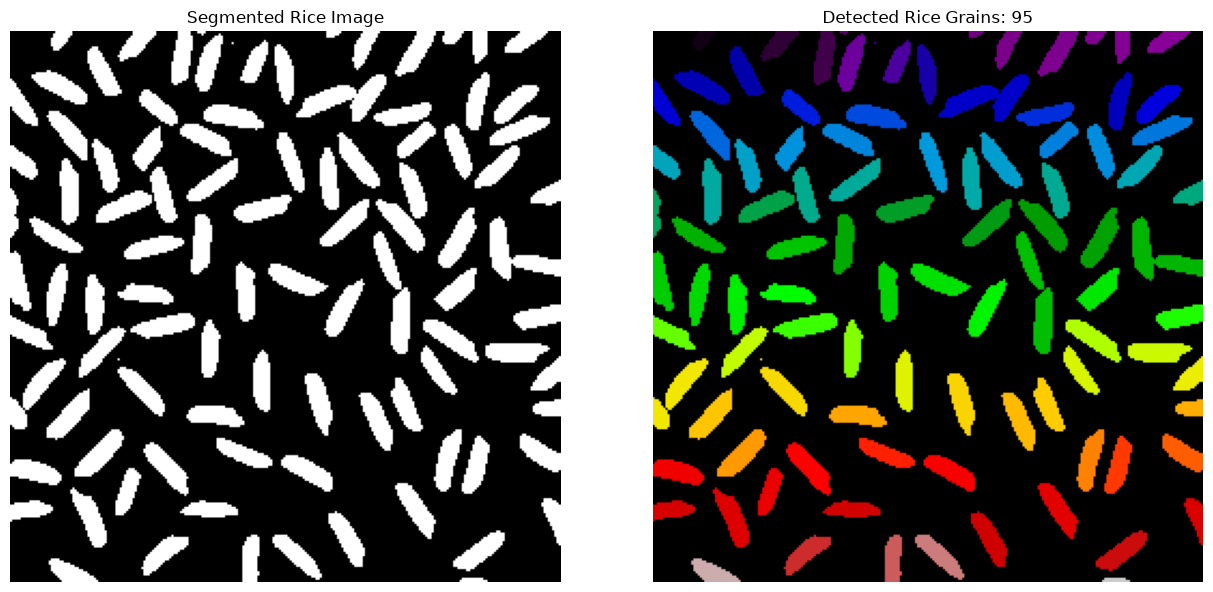

In [15]:

import cv2
import numpy as np
import matplotlib.pyplot as plt
from skimage.measure import label, regionprops

# Read segmented rice image
path = r"C:\Users\nitud\Downloads\segmented_rice.png"
img = cv2.imread(path, cv2.IMREAD_GRAYSCALE)

if img is None:
    print("Error: Image not found!")
    raise SystemExit

# Convert segmented image to binary
_, binary = cv2.threshold(
    img, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU
)

# If rice grains are black on white background, invert the image
if np.mean(binary == 255) > 0.5:
    binary = cv2.bitwise_not(binary)

# Label rice grains
labeled_img = label(binary > 0)
regions = regionprops(labeled_img)

# Remove very small noise
min_area = 20
rice = [p for p in regions if p.area >= min_area]

# Specific area range
min_range = 100
max_range = 500

selected = [
    p for p in rice
    if min_range <= p.area <= max_range
]

# Display results
print("\n========== RICE ANALYSIS ==========")
print("Total number of rice grains:", len(rice))
print(f"Rice grains with area {min_range}-{max_range}:",
      len(selected))

print("\nNo. | Area | Major Axis Length | Perimeter")
print("-" * 48)

for i, p in enumerate(rice, start=1):
    print(f"{i:3d} | {p.area:6.0f} | "
          f"{p.major_axis_length:17.2f} | "
          f"{p.perimeter:9.2f}")

print(f"\nRice grains in area range {min_range}-{max_range}:")
for i, p in enumerate(selected, start=1):
    print(f"Rice {i}: Area={p.area:.0f}, "
          f"Major Axis={p.major_axis_length:.2f}, "
          f"Perimeter={p.perimeter:.2f}")

# Display original and labelled images
plt.figure(figsize=(13, 6))

plt.subplot(1, 2, 1)
plt.imshow(img, cmap="gray")
plt.title("Segmented Rice Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(labeled_img, cmap="nipy_spectral")
plt.title(f"Detected Rice Grains: {len(rice)}")
plt.axis("off")

plt.tight_layout()
plt.show()


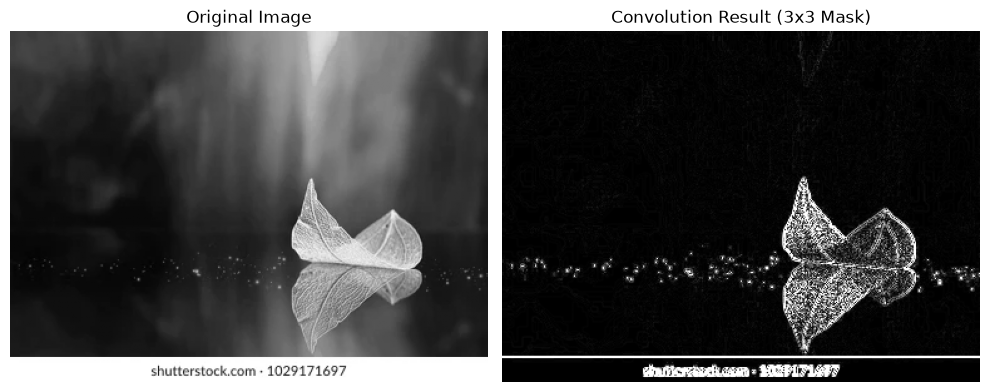

3x3 Mask:
[[ 1.  1.  1.]
 [ 1. -8.  1.]
 [ 1.  1.  1.]]
Convolution completed successfully.


In [16]:
#Write a MATLAB/Python program to read an image and perform convolution with 3X3 mask.

import cv2
import numpy as np
import matplotlib.pyplot as plt

# Read image
img = cv2.imread(r"C:\Users\nitud\Downloads\image.jpg.webp",
                 cv2.IMREAD_GRAYSCALE)

if img is None:
    print("Error: Image not found!")
    raise SystemExit

# Define 3x3 convolution mask
mask = np.array([
    [1, 1, 1],
    [1, -8, 1],
    [1, 1, 1]
], dtype=np.float32)

# Perform convolution
result = cv2.filter2D(img, cv2.CV_32F, mask)

# Convert result for display
result_display = cv2.convertScaleAbs(result)

# Display images
plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.imshow(img, cmap="gray")
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(result_display, cmap="gray")
plt.title("Convolution Result (3x3 Mask)")
plt.axis("off")

plt.tight_layout()
plt.show()

print("3x3 Mask:")
print(mask)
print("Convolution completed successfully.")


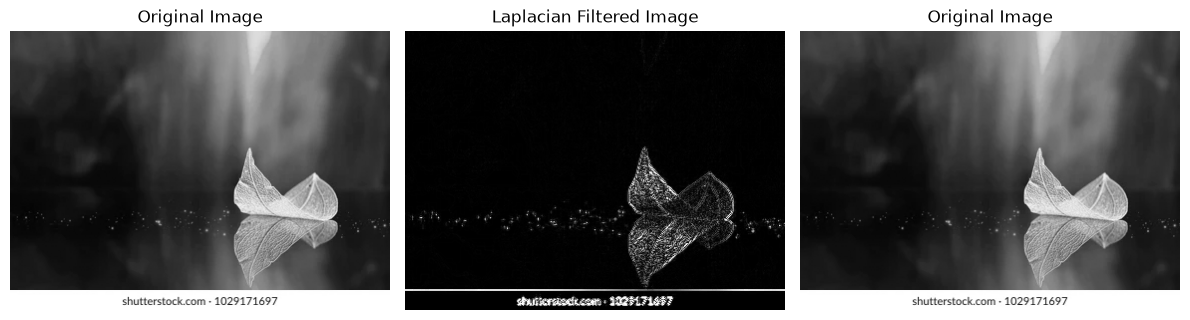

Laplacian Filter Mask:
[[ 0.  1.  0.]
 [ 1. -4.  1.]
 [ 0.  1.  0.]]
Laplacian filtering completed successfully.


In [17]:
#Write a MATLAB/Python program to read an image and perform Lapliciant filter mask.

import cv2
import numpy as np
import matplotlib.pyplot as plt

# Read image
img = cv2.imread(
    r"C:\Users\nitud\Downloads\image.jpg.webp",
    cv2.IMREAD_GRAYSCALE
)

if img is None:
    print("Error: Image not found!")
    raise SystemExit

# Define Laplacian filter mask (3x3)
mask = np.array([
    [0,  1,  0],
    [1, -4,  1],
    [0,  1,  0]
], dtype=np.float32)

# Apply Laplacian filter
laplacian = cv2.filter2D(img, cv2.CV_32F, mask)

# Convert result to display format
result = cv2.convertScaleAbs(laplacian)

# Display images
plt.figure(figsize=(12, 5))

plt.subplot(1, 3, 1)
plt.imshow(img, cmap="gray")
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(result, cmap="gray")
plt.title("Laplacian Filtered Image")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(img, cmap="gray")
plt.title("Original Image")
plt.axis("off")

plt.tight_layout()
plt.show()

print("Laplacian Filter Mask:")
print(mask)
print("Laplacian filtering completed successfully.")


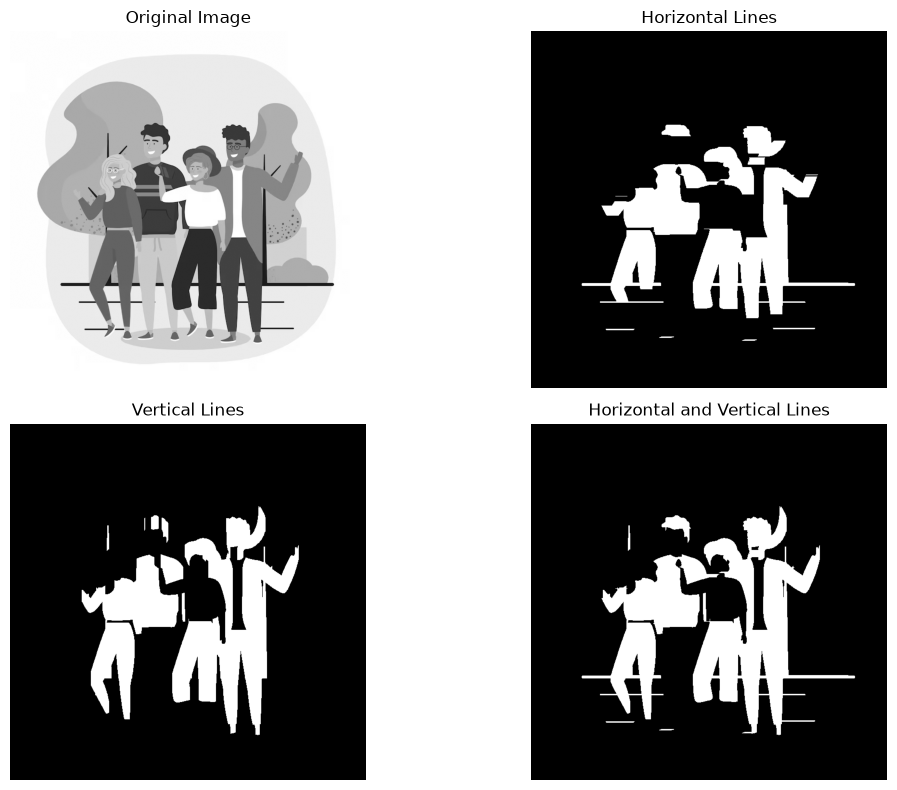

Line detection completed successfully.


In [20]:

import cv2
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

# Read AVIF image using Pillow
path = r"C:\Users\nitud\Downloads\girls-boys-with-casual-clothes-smartphone-selfie_24640-46948.avif"

try:
    img = Image.open(path).convert("L")
    img = np.array(img)
except Exception as e:
    print("Error loading image:", e)
    raise SystemExit

# Apply binary threshold
_, binary = cv2.threshold(
    img, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU
)

# Horizontal line detection
horizontal_kernel = cv2.getStructuringElement(
    cv2.MORPH_RECT, (25, 1)
)
horizontal_lines = cv2.morphologyEx(
    binary, cv2.MORPH_OPEN, horizontal_kernel
)

# Vertical line detection
vertical_kernel = cv2.getStructuringElement(
    cv2.MORPH_RECT, (1, 25)
)
vertical_lines = cv2.morphologyEx(
    binary, cv2.MORPH_OPEN, vertical_kernel
)

# Combined result
combined = cv2.bitwise_or(horizontal_lines, vertical_lines)

# Display results
plt.figure(figsize=(12, 8))

plt.subplot(2, 2, 1)
plt.imshow(img, cmap="gray")
plt.title("Original Image")
plt.axis("off")

plt.subplot(2, 2, 2)
plt.imshow(horizontal_lines, cmap="gray")
plt.title("Horizontal Lines")
plt.axis("off")

plt.subplot(2, 2, 3)
plt.imshow(vertical_lines, cmap="gray")
plt.title("Vertical Lines")
plt.axis("off")

plt.subplot(2, 2, 4)
plt.imshow(combined, cmap="gray")
plt.title("Horizontal and Vertical Lines")
plt.axis("off")

plt.tight_layout()
plt.show()

print("Line detection completed successfully.")


In [21]:
%pip install opencv-python numpy matplotlib

Note: you may need to restart the kernel to use updated packages.


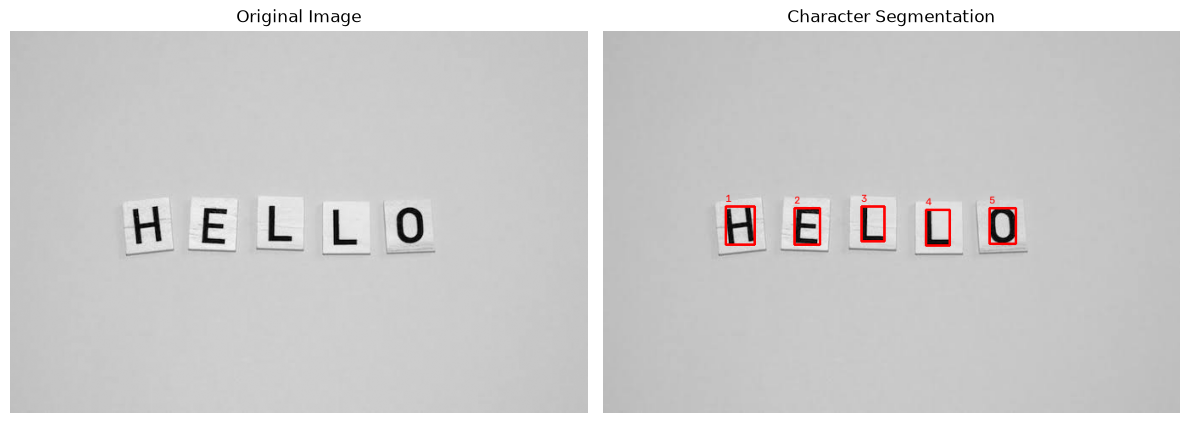

Total detected character components: 5


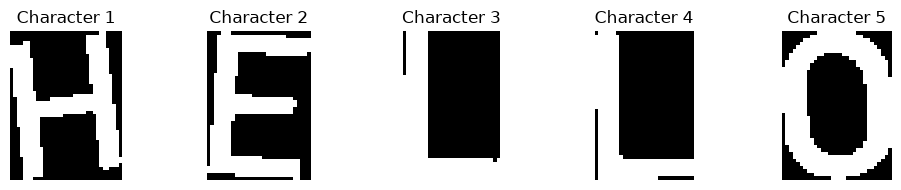

In [24]:
#Write a MATLAB/Python program to Character Segment of an image. 

import cv2
import numpy as np
import matplotlib.pyplot as plt

# Read input image
path = r"C:\Users\nitud\Downloads\hello.jpeg"
img = cv2.imread(path, cv2.IMREAD_GRAYSCALE)

if img is None:
    print("Error: Image not found!")
    raise SystemExit

# Convert image to binary
_, binary = cv2.threshold(
    img, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU
)

# Find connected components
num_labels, labels, stats, centroids = cv2.connectedComponentsWithStats(
    binary, connectivity=8
)

# Store character regions
characters = []

for i in range(1, num_labels):
    x, y, w, h, area = stats[i]

    # Remove small noise
    if area > 10 and w > 2 and h > 5:
        characters.append((x, y, w, h))

# Sort characters from left to right
characters.sort(key=lambda c: c[0])

# Draw rectangles around detected characters
output = cv2.cvtColor(img, cv2.COLOR_GRAY2RGB)

for i, (x, y, w, h) in enumerate(characters, start=1):
    cv2.rectangle(output, (x, y), (x + w, y + h), (255, 0, 0), 2)
    cv2.putText(
        output, str(i), (x, max(y - 5, 10)),
        cv2.FONT_HERSHEY_SIMPLEX, 0.4, (255, 0, 0), 1
    )

# Display original and segmented characters
plt.figure(figsize=(12, 6))

plt.subplot(1, 2, 1)
plt.imshow(img, cmap="gray")
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(output)
plt.title("Character Segmentation")
plt.axis("off")

plt.tight_layout()
plt.show()

# Display each segmented character
print("Total detected character components:", len(characters))

if characters:
    cols = 5
    rows = (len(characters) + cols - 1) // cols

    plt.figure(figsize=(10, 2 * rows))

    for i, (x, y, w, h) in enumerate(characters):
        char_img = binary[y:y+h, x:x+w]

        plt.subplot(rows, cols, i + 1)
        plt.imshow(char_img, cmap="gray")
        plt.title(f"Character {i+1}")
        plt.axis("off")

    plt.tight_layout()
    plt.show()
else:
    print("No characters detected.")


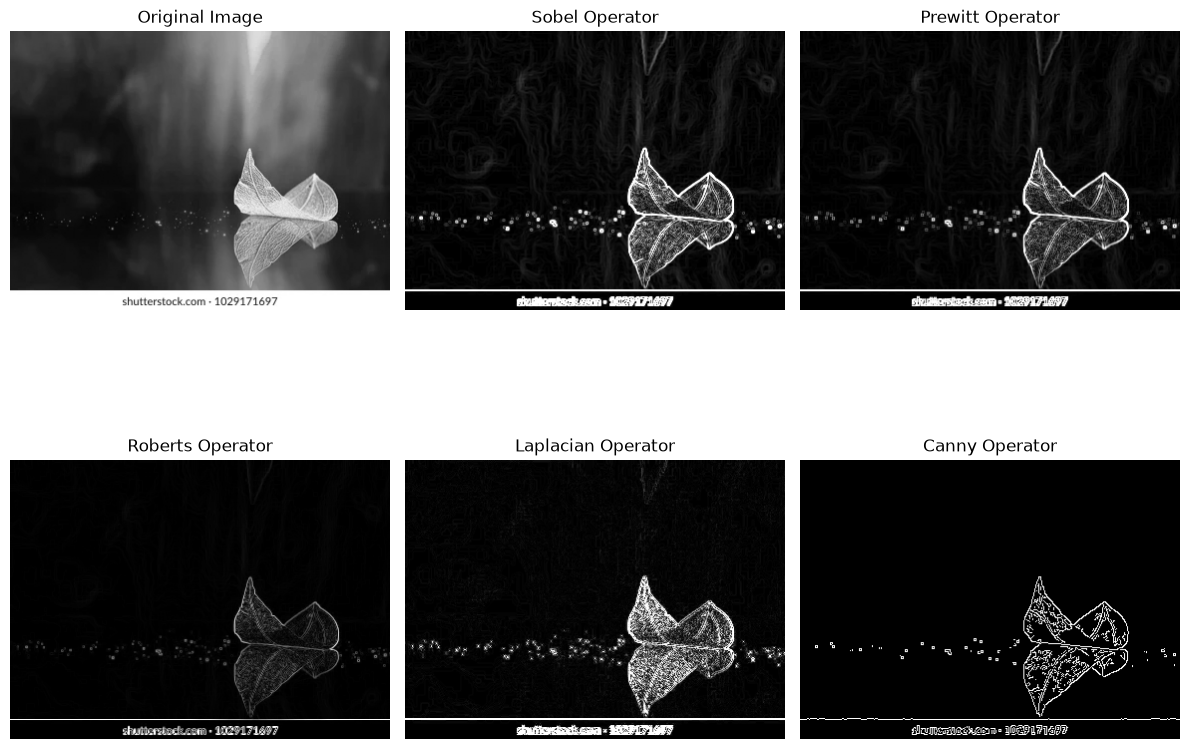

Edge detection using different operators completed.


In [25]:
#For the given image perform edge detection using different operators and compare the results.

import cv2
import numpy as np
import matplotlib.pyplot as plt

# Read image
path = r"C:\Users\nitud\Downloads\image.jpg.webp"
img = cv2.imread(path, cv2.IMREAD_GRAYSCALE)

if img is None:
    print("Error: Image not found!")
    raise SystemExit

# 1. Sobel Operator
sobel_x = cv2.Sobel(img, cv2.CV_64F, 1, 0, ksize=3)
sobel_y = cv2.Sobel(img, cv2.CV_64F, 0, 1, ksize=3)
sobel = cv2.magnitude(sobel_x, sobel_y)
sobel = cv2.convertScaleAbs(sobel)

# 2. Prewitt Operator
prewitt_x_mask = np.array([
    [-1, 0, 1],
    [-1, 0, 1],
    [-1, 0, 1]
], dtype=np.float32)

prewitt_y_mask = np.array([
    [-1, -1, -1],
    [ 0,  0,  0],
    [ 1,  1,  1]
], dtype=np.float32)

prewitt_x = cv2.filter2D(img, cv2.CV_32F, prewitt_x_mask)
prewitt_y = cv2.filter2D(img, cv2.CV_32F, prewitt_y_mask)
prewitt = cv2.magnitude(prewitt_x, prewitt_y)
prewitt = cv2.convertScaleAbs(prewitt)

# 3. Roberts Operator
roberts_x_mask = np.array([
    [1, 0],
    [0, -1]
], dtype=np.float32)

roberts_y_mask = np.array([
    [0, 1],
    [-1, 0]
], dtype=np.float32)

roberts_x = cv2.filter2D(img, cv2.CV_32F, roberts_x_mask)
roberts_y = cv2.filter2D(img, cv2.CV_32F, roberts_y_mask)
roberts = cv2.magnitude(roberts_x, roberts_y)
roberts = cv2.convertScaleAbs(roberts)

# 4. Laplacian Operator
laplacian = cv2.Laplacian(img, cv2.CV_64F, ksize=3)
laplacian = cv2.convertScaleAbs(laplacian)

# 5. Canny Edge Detection
canny = cv2.Canny(img, 100, 200)

# Display and compare results
images = [
    ("Original Image", img),
    ("Sobel Operator", sobel),
    ("Prewitt Operator", prewitt),
    ("Roberts Operator", roberts),
    ("Laplacian Operator", laplacian),
    ("Canny Operator", canny)
]

plt.figure(figsize=(12, 10))

for i, (title, result) in enumerate(images, start=1):
    plt.subplot(2, 3, i)
    plt.imshow(result, cmap="gray")
    plt.title(title)
    plt.axis("off")

plt.tight_layout()
plt.show()

print("Edge detection using different operators completed.")


Total number of coins: 6

Coin No.     Area (pixels^2)
----------------------------
       1     21166
       2     21118
       3     18068
       4     20288
       5     21603
       6     21421


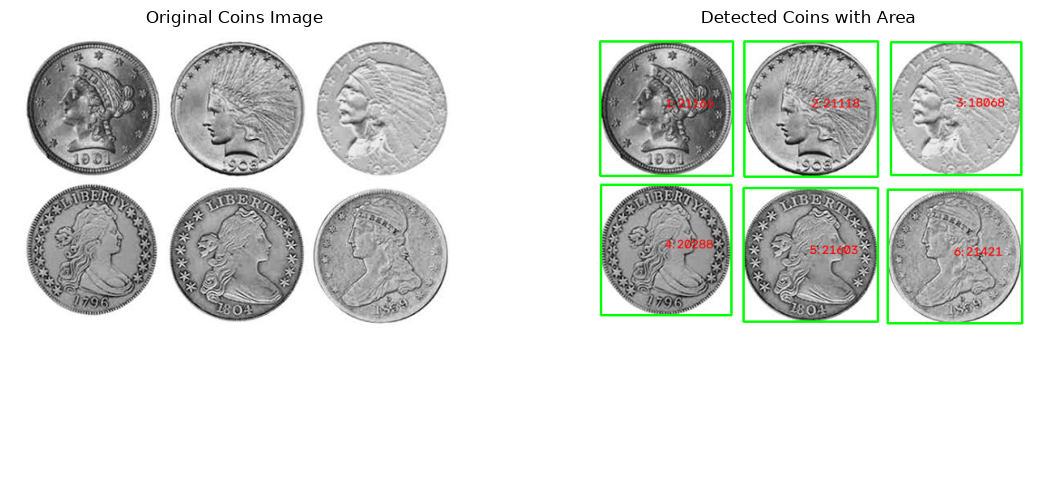

In [26]:
#Write a MATLAB/Python program to read coins.png, leveling all coins and display area of all coins.

import cv2
import numpy as np
import matplotlib.pyplot as plt
from skimage.measure import label, regionprops

# Read coins image
path = r"C:\Users\nitud\Downloads\coin.jpeg"
img = cv2.imread(path, cv2.IMREAD_GRAYSCALE)

if img is None:
    print("Error: coins.png not found!")
    raise SystemExit

# Apply Gaussian blur
blur = cv2.GaussianBlur(img, (5, 5), 0)

# Convert image to binary
_, binary = cv2.threshold(
    blur, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU
)

# Fill small gaps and remove noise
kernel = np.ones((3, 3), np.uint8)
binary = cv2.morphologyEx(binary, cv2.MORPH_CLOSE, kernel)
binary = cv2.morphologyEx(binary, cv2.MORPH_OPEN, kernel)

# Label connected coins
labels = label(binary > 0)
regions = regionprops(labels)

# Remove small unwanted regions
coins = [p for p in regions if p.area > 100]

# Display coin count and area
print("Total number of coins:", len(coins))
print("\nCoin No.     Area (pixels^2)")
print("----------------------------")

# Prepare output image
output = cv2.cvtColor(img, cv2.COLOR_GRAY2RGB)

for i, coin in enumerate(coins, start=1):
    area = coin.area
    y, x = coin.centroid

    print(f"{i:8d}     {area:.0f}")

    # Draw bounding box and label
    minr, minc, maxr, maxc = coin.bbox
    cv2.rectangle(
        output, (minc, minr), (maxc, maxr),
        (0, 255, 0), 2
    )

    cv2.putText(
        output, f"{i}: {area:.0f}",
        (int(x), int(y)),
        cv2.FONT_HERSHEY_SIMPLEX, 0.5,
        (255, 0, 0), 1
    )

# Display images
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(img, cmap="gray")
plt.title("Original Coins Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(output)
plt.title("Detected Coins with Area")
plt.axis("off")

plt.tight_layout()
plt.show()


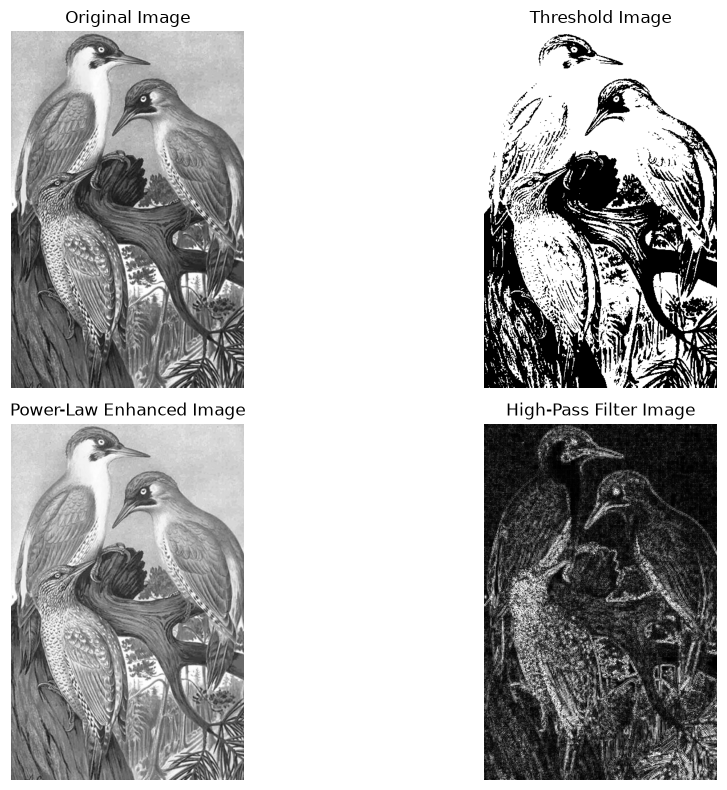

All image operations completed successfully.


In [29]:
#Display following image operation in MATLAB/Python - i) Threshold image ii) Power enhance contract image iii) High pass image.

import cv2
import numpy as np
import matplotlib.pyplot as plt

# Read image
path = r"C:\Users\nitud\Downloads\Pic_vert.jpg"
img = cv2.imread(path, cv2.IMREAD_GRAYSCALE)

if img is None:
    print("Error: Image not found!")
    raise SystemExit

# i) Threshold Image
_, threshold_img = cv2.threshold(
    img, 127, 255, cv2.THRESH_BINARY
)

# ii) Power Law (Gamma) Contrast Enhancement
gamma = 0.5
normalized = img.astype(np.float32) / 255.0
power_img = np.power(normalized, gamma)
power_img = np.uint8(power_img * 255)

# iii) High-Pass Filter Image
mask = np.array([
    [-1, -1, -1],
    [-1,  8, -1],
    [-1, -1, -1]
], dtype=np.float32)

high_pass = cv2.filter2D(img, cv2.CV_32F, mask)
high_pass = cv2.convertScaleAbs(high_pass)

# Display all images
plt.figure(figsize=(12, 8))

plt.subplot(2, 2, 1)
plt.imshow(img, cmap="gray")
plt.title("Original Image")
plt.axis("off")

plt.subplot(2, 2, 2)
plt.imshow(threshold_img, cmap="gray")
plt.title("Threshold Image")
plt.axis("off")

plt.subplot(2, 2, 3)
plt.imshow(power_img, cmap="gray")
plt.title("Power-Law Enhanced Image")
plt.axis("off")

plt.subplot(2, 2, 4)
plt.imshow(high_pass, cmap="gray")
plt.title("High-Pass Filter Image")
plt.axis("off")

plt.tight_layout()
plt.show()

print("All image operations completed successfully.")


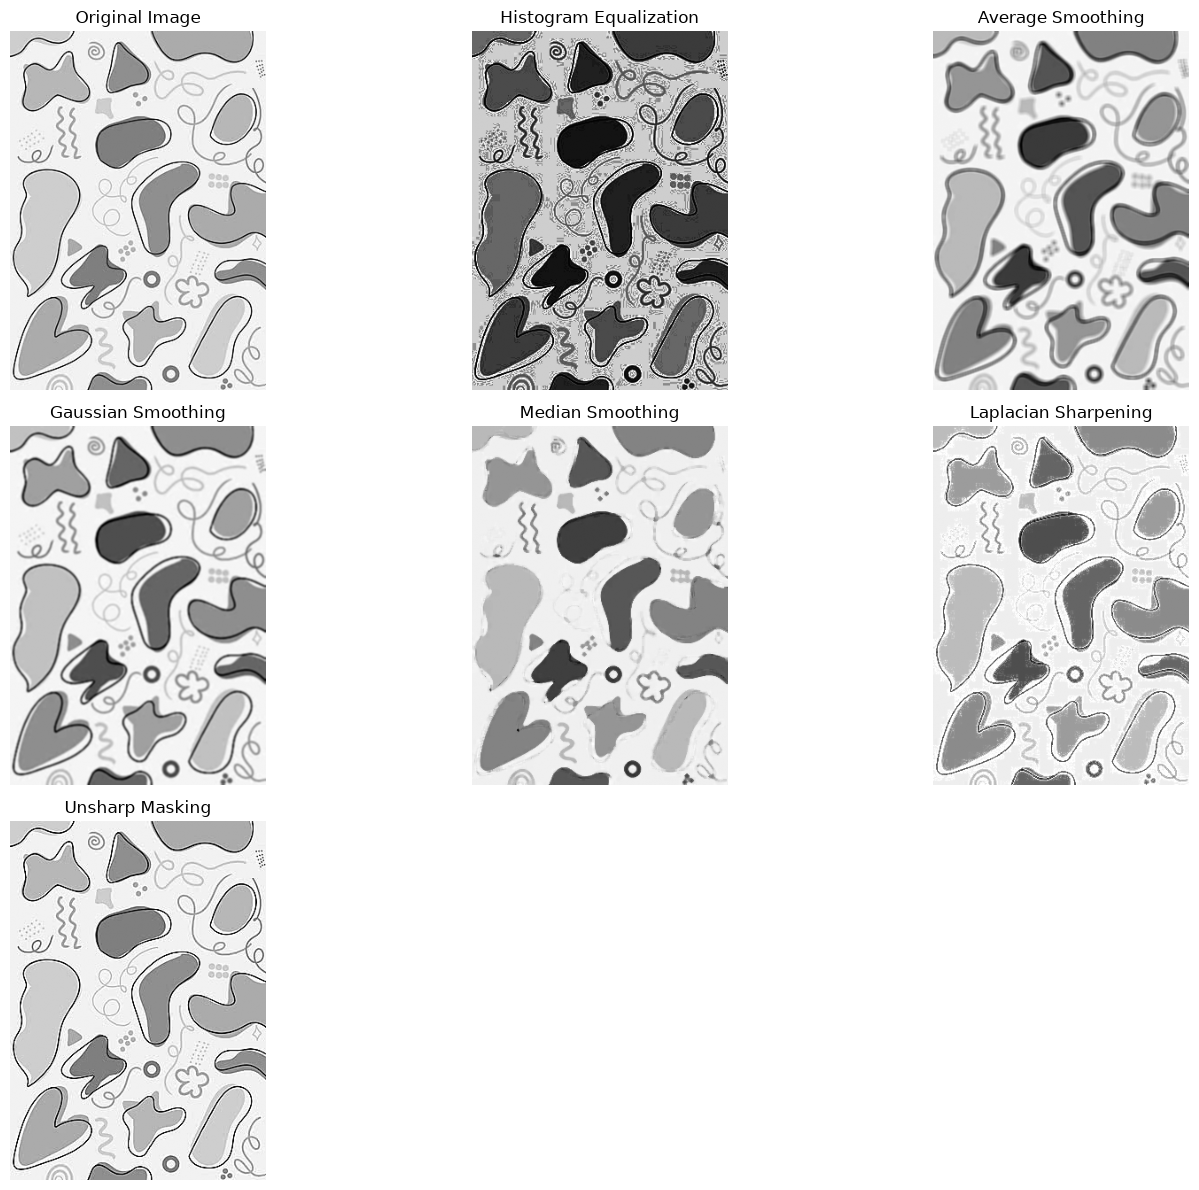

Image enhancement, smoothing and sharpening completed.


In [31]:
#Perform image enhancement, smoothing and sharpening, in spatial domain using different spatial filters and compare the performances 

import cv2
import numpy as np
import matplotlib.pyplot as plt

# Read image
path = r"C:\Users\nitud\Downloads\asthetic.jpg"
img = cv2.imread(path, cv2.IMREAD_GRAYSCALE)

if img is None:
    print("Error: Image not found!")
    raise SystemExit

# 1. Image Enhancement: Histogram Equalization
enhanced = cv2.equalizeHist(img)

# 2. Smoothing Filters
# Average filter
average = cv2.blur(img, (5, 5))

# Gaussian filter
gaussian = cv2.GaussianBlur(img, (5, 5), 0)

# Median filter
median = cv2.medianBlur(img, 5)

# 3. Sharpening Filters
# Laplacian sharpening
laplacian = cv2.Laplacian(img, cv2.CV_64F)
laplacian = cv2.convertScaleAbs(laplacian)
sharpened_laplacian = cv2.addWeighted(
    img, 1.0, laplacian, 0.5, 0
)

# Unsharp masking
blurred = cv2.GaussianBlur(img, (5, 5), 0)
unsharp = cv2.addWeighted(img, 1.5, blurred, -0.5, 0)

# Display results
images = [
    ("Original Image", img),
    ("Histogram Equalization", enhanced),
    ("Average Smoothing", average),
    ("Gaussian Smoothing", gaussian),
    ("Median Smoothing", median),
    ("Laplacian Sharpening", sharpened_laplacian),
    ("Unsharp Masking", unsharp)
]

plt.figure(figsize=(14, 12))

for i, (title, result) in enumerate(images, 1):
    plt.subplot(3, 3, i)
    plt.imshow(result, cmap="gray")
    plt.title(title)
    plt.axis("off")

plt.tight_layout()
plt.show()

print("Image enhancement, smoothing and sharpening completed.")


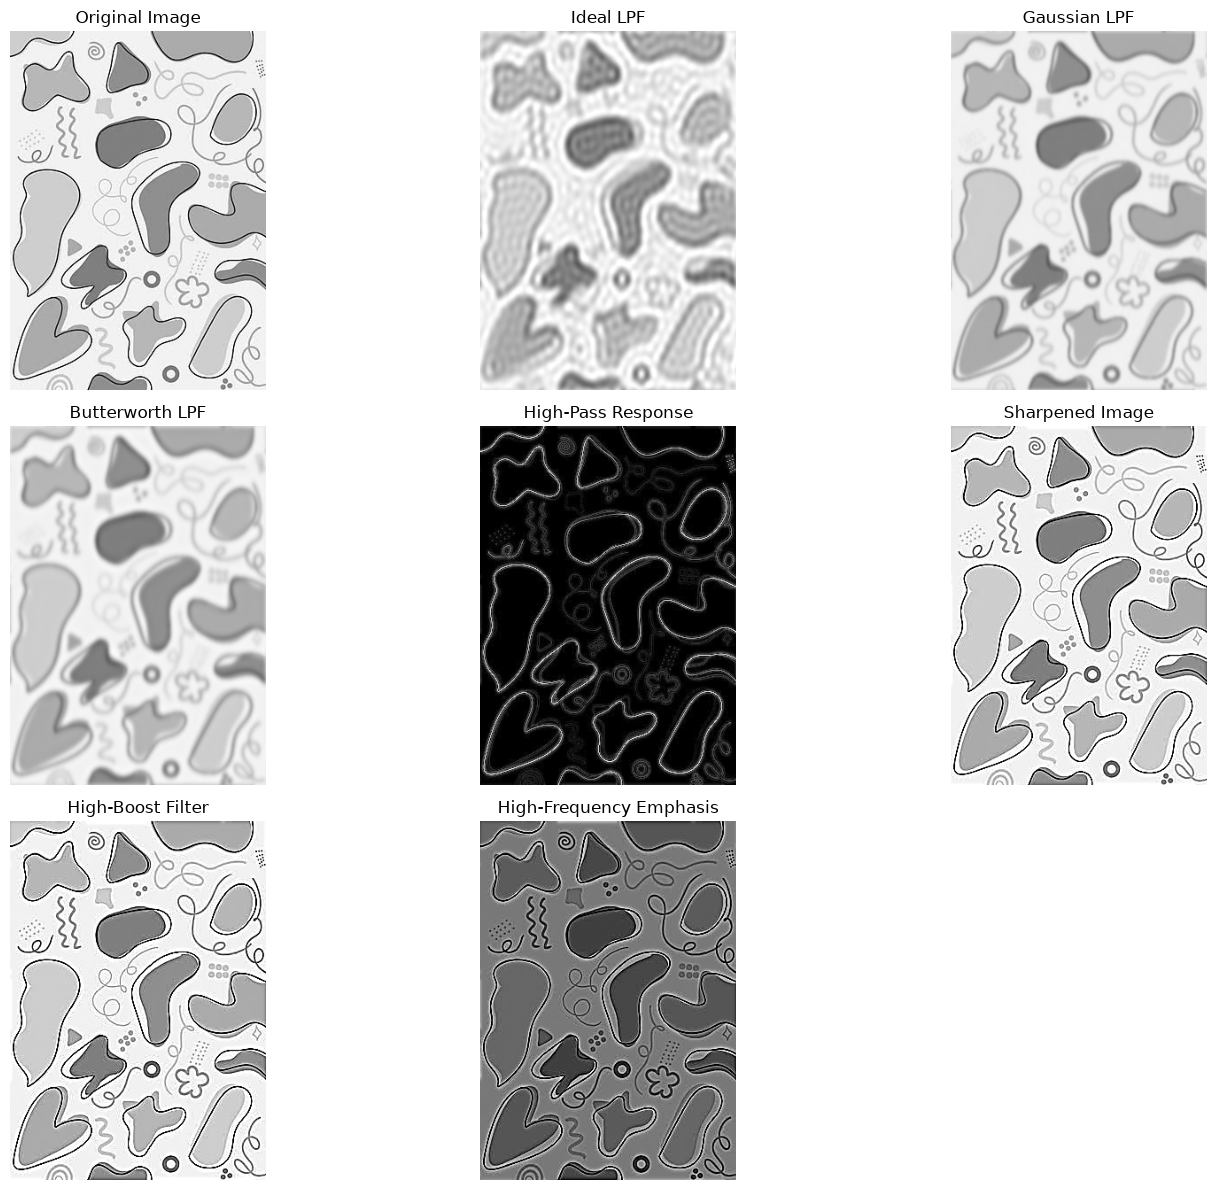

Frequency-domain filtering completed successfully.


In [32]:
#Perform image enhancement, smoothing and sharpening, in frequency domain using different filters and compare the performances 

import cv2
import numpy as np
import matplotlib.pyplot as plt

# Read the image
path = r"C:\Users\nitud\Downloads\asthetic.jpg"
img = cv2.imread(path, cv2.IMREAD_GRAYSCALE)

if img is None:
    print("Error: Image not found! Check the file path.")
    raise SystemExit

# Convert image to frequency domain
img_float = np.float32(img)
rows, cols = img.shape
crow, ccol = rows // 2, cols // 2

F = np.fft.fft2(img_float)
F_shift = np.fft.fftshift(F)

# Create distance matrix from the frequency center
u, v = np.ogrid[:rows, :cols]
D = np.sqrt((u - crow)**2 + (v - ccol)**2)

D0 = 30  # Cutoff frequency

# 1. Ideal Low-Pass Filter
ideal_lpf = np.zeros((rows, cols), dtype=np.float32)
ideal_lpf[D <= D0] = 1

# 2. Gaussian Low-Pass Filter
gaussian_lpf = np.exp(-(D**2) / (2 * D0**2))

# 3. Butterworth Low-Pass Filter
n = 2
butterworth_lpf = 1 / (1 + (D / D0)**(2 * n))

# Function to apply a frequency-domain filter
def apply_filter(F_shift, H):
    filtered = F_shift * H
    inverse = np.fft.ifft2(np.fft.ifftshift(filtered))
    return np.real(inverse)

# 4. Smoothing filters
ideal_smooth = apply_filter(F_shift, ideal_lpf)
gaussian_smooth = apply_filter(F_shift, gaussian_lpf)
butterworth_smooth = apply_filter(F_shift, butterworth_lpf)

# 5. High-Pass Filter
highpass = 1 - gaussian_lpf
highpass_result = apply_filter(F_shift, highpass)

# 6. Sharpening
sharpened = img_float + highpass_result

# 7. High-Boost Filtering
k = 1.5
high_boost = apply_filter(F_shift, 1 + k * highpass)

# 8. High-Frequency Emphasis Enhancement
a, b = 0.5, 1.5
hfe_filter = a + b * highpass
enhanced = apply_filter(F_shift, hfe_filter)

# Convert results to displayable images
def to_uint8(image):
    return np.clip(image, 0, 255).astype(np.uint8)

ideal_smooth = to_uint8(ideal_smooth)
gaussian_smooth = to_uint8(gaussian_smooth)
butterworth_smooth = to_uint8(butterworth_smooth)
sharpened = to_uint8(sharpened)
high_boost = to_uint8(high_boost)
enhanced = to_uint8(enhanced)

# Normalize high-pass response for visualization
highpass_display = cv2.normalize(
    np.abs(highpass_result), None, 0, 255, cv2.NORM_MINMAX
).astype(np.uint8)

# Display and compare results
images = [
    ("Original Image", img),
    ("Ideal LPF", ideal_smooth),
    ("Gaussian LPF", gaussian_smooth),
    ("Butterworth LPF", butterworth_smooth),
    ("High-Pass Response", highpass_display),
    ("Sharpened Image", sharpened),
    ("High-Boost Filter", high_boost),
    ("High-Frequency Emphasis", enhanced)
]

plt.figure(figsize=(15, 12))

for i, (title, result) in enumerate(images, 1):
    plt.subplot(3, 3, i)
    plt.imshow(result, cmap="gray", vmin=0, vmax=255)
    plt.title(title)
    plt.axis("off")

plt.tight_layout()
plt.show()

print("Frequency-domain filtering completed successfully.")


In [33]:
%pip install numpy matplotlib librosa soundfile

Note: you may need to restart the kernel to use updated packages.


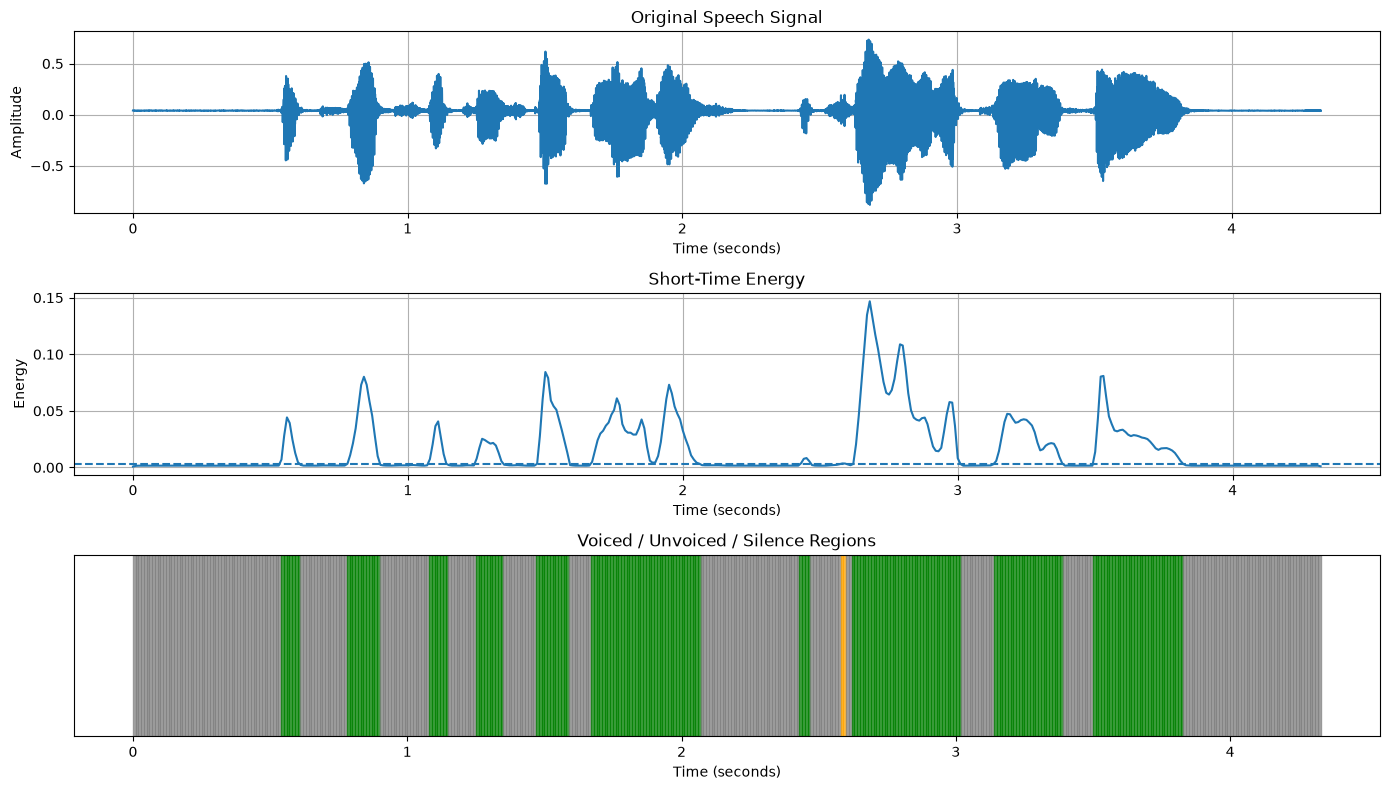

Detected speech regions:
Silence: 0.00s - 0.54s
Voiced: 0.54s - 0.61s
Silence: 0.61s - 0.78s
Voiced: 0.78s - 0.90s
Silence: 0.90s - 1.08s
Voiced: 1.08s - 1.15s
Silence: 1.15s - 1.25s
Voiced: 1.25s - 1.35s
Silence: 1.35s - 1.47s
Voiced: 1.47s - 1.59s
Silence: 1.59s - 1.67s
Voiced: 1.67s - 2.07s
Silence: 2.07s - 2.43s
Voiced: 2.43s - 2.47s
Silence: 2.47s - 2.58s
Unvoiced: 2.58s - 2.60s
Silence: 2.60s - 2.62s
Voiced: 2.62s - 3.02s
Silence: 3.02s - 3.14s
Voiced: 3.14s - 3.39s
Silence: 3.39s - 3.50s
Voiced: 3.50s - 3.83s
Silence: 3.83s - 4.33s


In [34]:
#Write a MATLAB/Python program to separation of voiced/un-voiced/silence regions from a speech signal.

import numpy as np
import librosa
import matplotlib.pyplot as plt

# Load speech signal
audio_path = r"C:\Users\nitud\Downloads\download.wav"

signal, sr = librosa.load(audio_path, sr=None, mono=True)

# Frame settings
frame_length = int(0.025 * sr)  # 25 ms
hop_length = int(0.010 * sr)    # 10 ms

# Short-Time Energy and Zero-Crossing Rate
energy = librosa.feature.rms(
    y=signal,
    frame_length=frame_length,
    hop_length=hop_length
)[0] ** 2

zcr = librosa.feature.zero_crossing_rate(
    y=signal,
    frame_length=frame_length,
    hop_length=hop_length
)[0]

times = librosa.frames_to_time(
    np.arange(len(energy)),
    sr=sr,
    hop_length=hop_length
)

# Thresholds
energy_threshold = max(np.max(energy) * 0.02, 1e-8)
zcr_threshold = 0.10

# Classify each frame
regions = []

for e, z in zip(energy, zcr):
    if e < energy_threshold:
        regions.append("Silence")
    elif z < zcr_threshold:
        regions.append("Voiced")
    else:
        regions.append("Unvoiced")

# Plot speech signal and classification
plt.figure(figsize=(14, 8))

plt.subplot(3, 1, 1)
time_axis = np.arange(len(signal)) / sr
plt.plot(time_axis, signal)
plt.title("Original Speech Signal")
plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude")
plt.grid()

plt.subplot(3, 1, 2)
plt.plot(times, energy)
plt.axhline(energy_threshold, linestyle="--")
plt.title("Short-Time Energy")
plt.xlabel("Time (seconds)")
plt.ylabel("Energy")
plt.grid()

plt.subplot(3, 1, 3)
colors = {
    "Voiced": "green",
    "Unvoiced": "orange",
    "Silence": "gray"
}

for i, region in enumerate(regions):
    plt.axvspan(
        times[i],
        times[i] + hop_length / sr,
        color=colors[region],
        alpha=0.7
    )

plt.title("Voiced / Unvoiced / Silence Regions")
plt.xlabel("Time (seconds)")
plt.yticks([])
plt.tight_layout()
plt.show()

# Print detected regions
print("Detected speech regions:")

start = 0
for i in range(1, len(regions) + 1):
    if i == len(regions) or regions[i] != regions[start]:
        end_time = times[start] + (i - start) * hop_length / sr
        print(
            f"{regions[start]}: "
            f"{times[start]:.2f}s - {end_time:.2f}s"
        )
        start = i


In [38]:
%pip install numpy librosa PyWavelets matplotlib soundfile

   ---------------------------------------- 0.0/4.3 MB ? eta -:--:--
   ---------------------------------------- 0.0/4.3 MB ? eta -:--:--
   -- ------------------------------------- 0.3/4.3 MB ? eta -:--:--
   ---- ----------------------------------- 0.5/4.3 MB 1.4 MB/s eta 0:00:03
   ------- -------------------------------- 0.8/4.3 MB 1.5 MB/s eta 0:00:03
   ------------ --------------------------- 1.3/4.3 MB 1.6 MB/s eta 0:00:02
   -------------- ------------------------- 1.6/4.3 MB 1.5 MB/s eta 0:00:02
   --------------------- ------------------ 2.4/4.3 MB 1.8 MB/s eta 0:00:02
   ----------------------------- ---------- 3.1/4.3 MB 2.1 MB/s eta 0:00:01
   ---------------------------------------  4.2/4.3 MB 2.5 MB/s eta 0:00:01
   ---------------------------------------- 4.3/4.3 MB 2.4 MB/s  0:00:02
Note: you may need to restart the kernel to use updated packages.


Quantization Error (MSE):
------------------------------------------
2-bit (  4 levels): MSE = 0.00638182
3-bit (  8 levels): MSE = 0.00407612
4-bit ( 16 levels): MSE = 0.00051060
8-bit (256 levels): MSE = 0.00000538


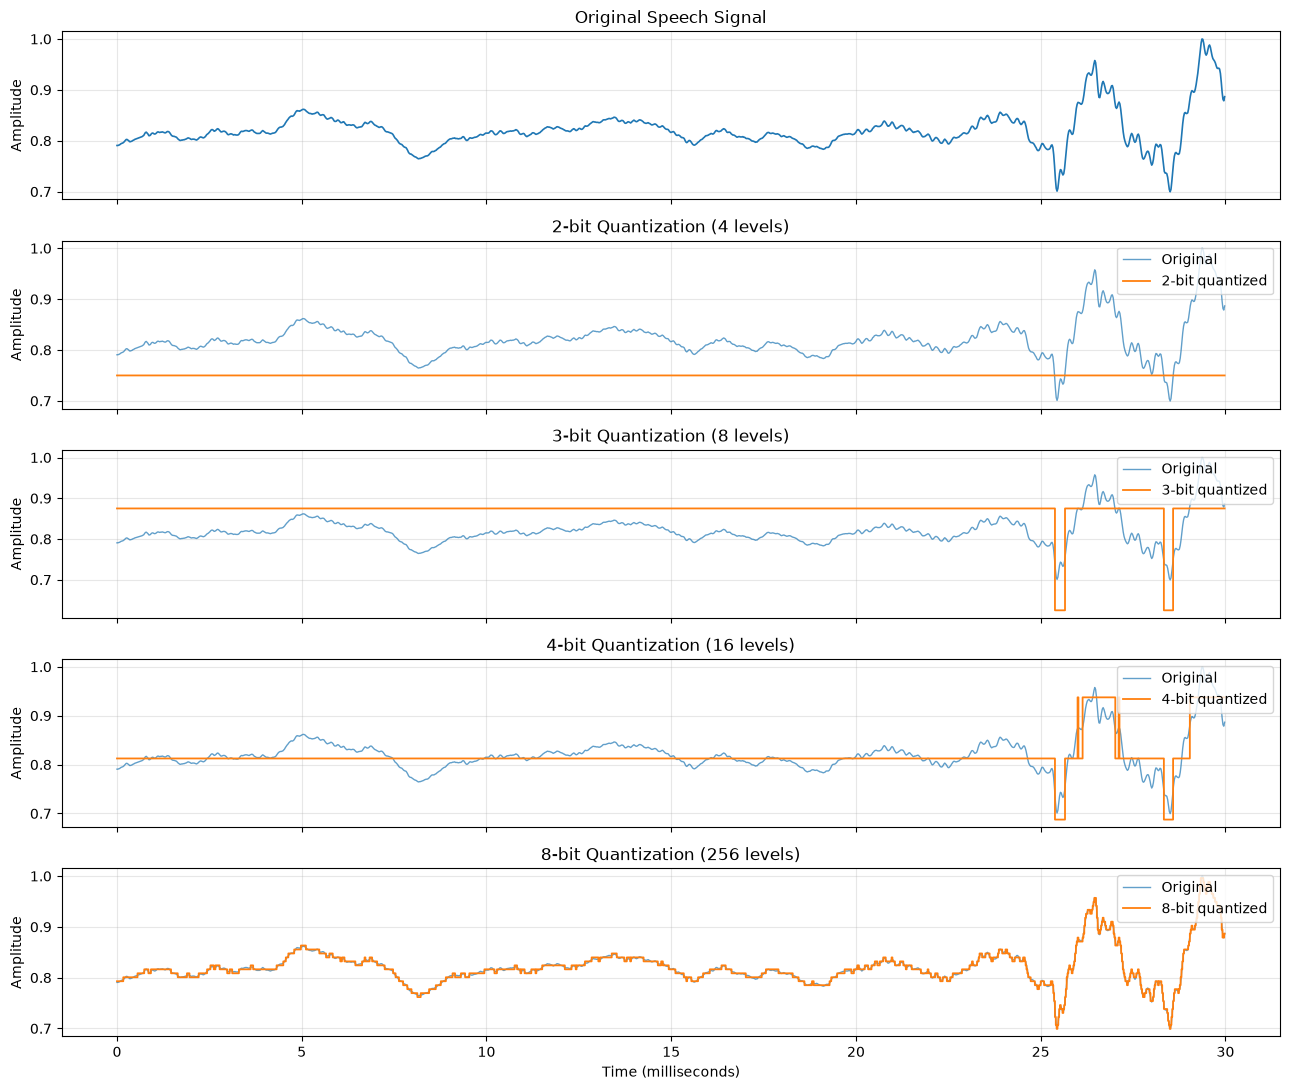

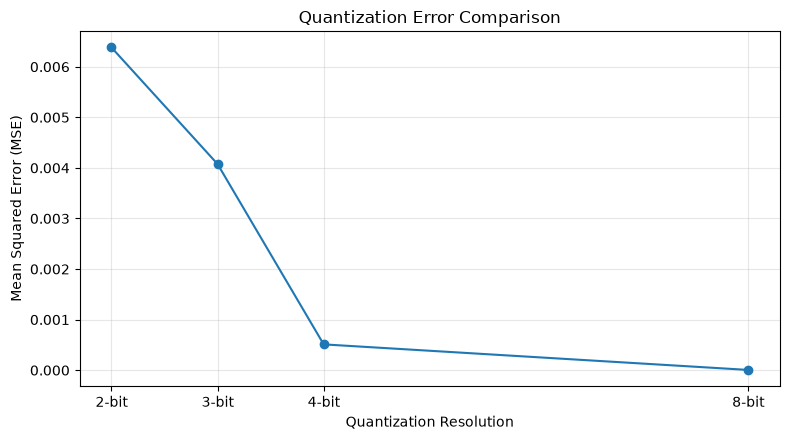

In [42]:
import numpy as np
import librosa
import matplotlib.pyplot as plt

# 1. Load speech audio
audio_path = r"C:\Users\nitud\Downloads\download.wav"

signal, sr = librosa.load(audio_path, sr=None, mono=True)

if len(signal) == 0:
    raise ValueError("Audio file is empty.")

# 2. Select a 30 ms segment with enough signal
duration = 0.03
start_time = 0.5  # Start at 0.5 seconds

start = int(start_time * sr)
end = start + int(duration * sr)

if end > len(signal):
    start = 0
    end = min(len(signal), int(duration * sr))

x = signal[start:end]

# Normalize the selected segment
peak = np.max(np.abs(x))
if peak == 0:
    raise ValueError("Selected speech segment contains only silence.")

x = x / peak
time = np.arange(len(x)) / sr * 1000  # milliseconds

# 3. Uniform mid-rise quantizer
def quantize(x, bits):
    levels = 2 ** bits
    step = 2.0 / levels

    index = np.floor((x + 1.0) / step)
    index = np.clip(index, 0, levels - 1)

    q = -1.0 + (index + 0.5) * step
    return q

# 4. Plot original and quantized signals
bits_list = [2, 3, 4, 8]
results = {}

fig, axes = plt.subplots(
    len(bits_list) + 1, 1,
    figsize=(13, 11),
    sharex=True
)

axes[0].plot(time, x, linewidth=1.2)
axes[0].set_title("Original Speech Signal")
axes[0].set_ylabel("Amplitude")
axes[0].grid(True, alpha=0.3)

print("Quantization Error (MSE):")
print("-" * 42)

for ax, bits in zip(axes[1:], bits_list):
    q = quantize(x, bits)
    mse = np.mean((x - q) ** 2)
    results[bits] = mse

    ax.plot(time, x, linewidth=1, label="Original", alpha=0.7)
    ax.step(time, q, where="mid", linewidth=1.3,
            label=f"{bits}-bit quantized")
    ax.set_title(f"{bits}-bit Quantization ({2**bits} levels)")
    ax.set_ylabel("Amplitude")
    ax.grid(True, alpha=0.3)
    ax.legend(loc="upper right")

    print(f"{bits}-bit ({2**bits:3d} levels): MSE = {mse:.8f}")

axes[-1].set_xlabel("Time (milliseconds)")
plt.tight_layout()
plt.show()

# 5. Plot MSE comparison
plt.figure(figsize=(8, 4.5))
bits = list(results.keys())
mse_values = list(results.values())

plt.plot(bits, mse_values, marker="o")
plt.xticks(bits, [f"{b}-bit" for b in bits])
plt.xlabel("Quantization Resolution")
plt.ylabel("Mean Squared Error (MSE)")
plt.title("Quantization Error Comparison")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

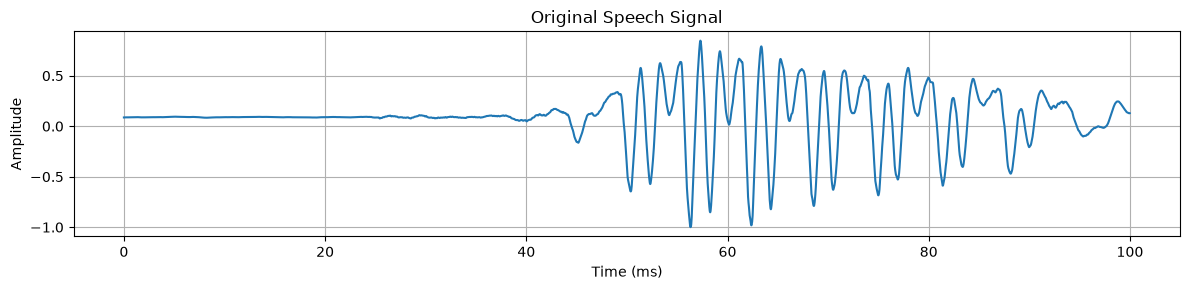

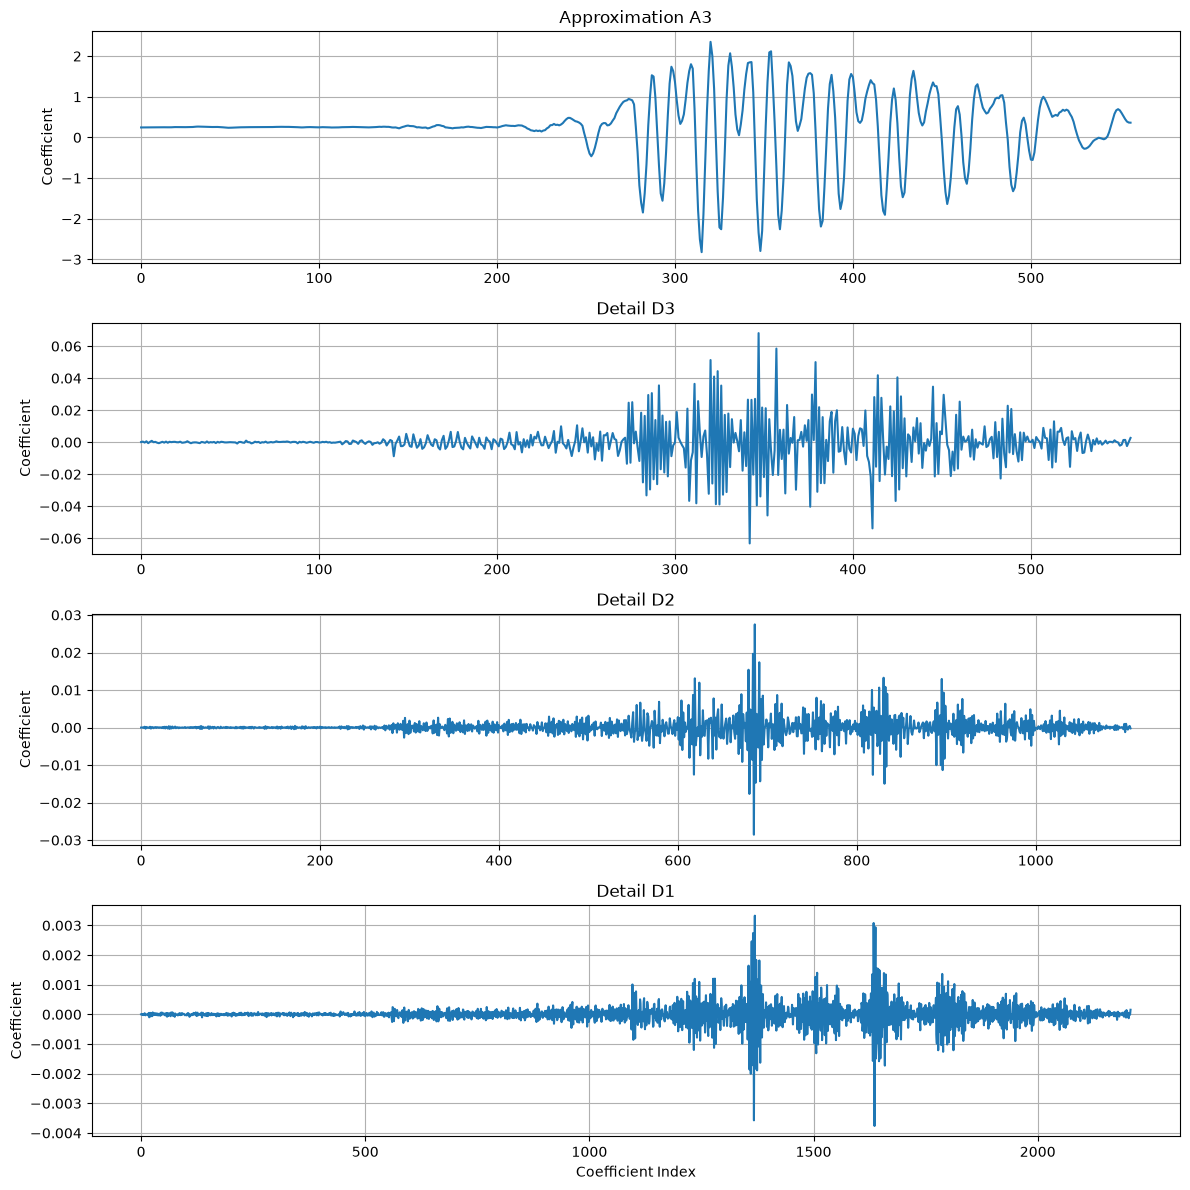

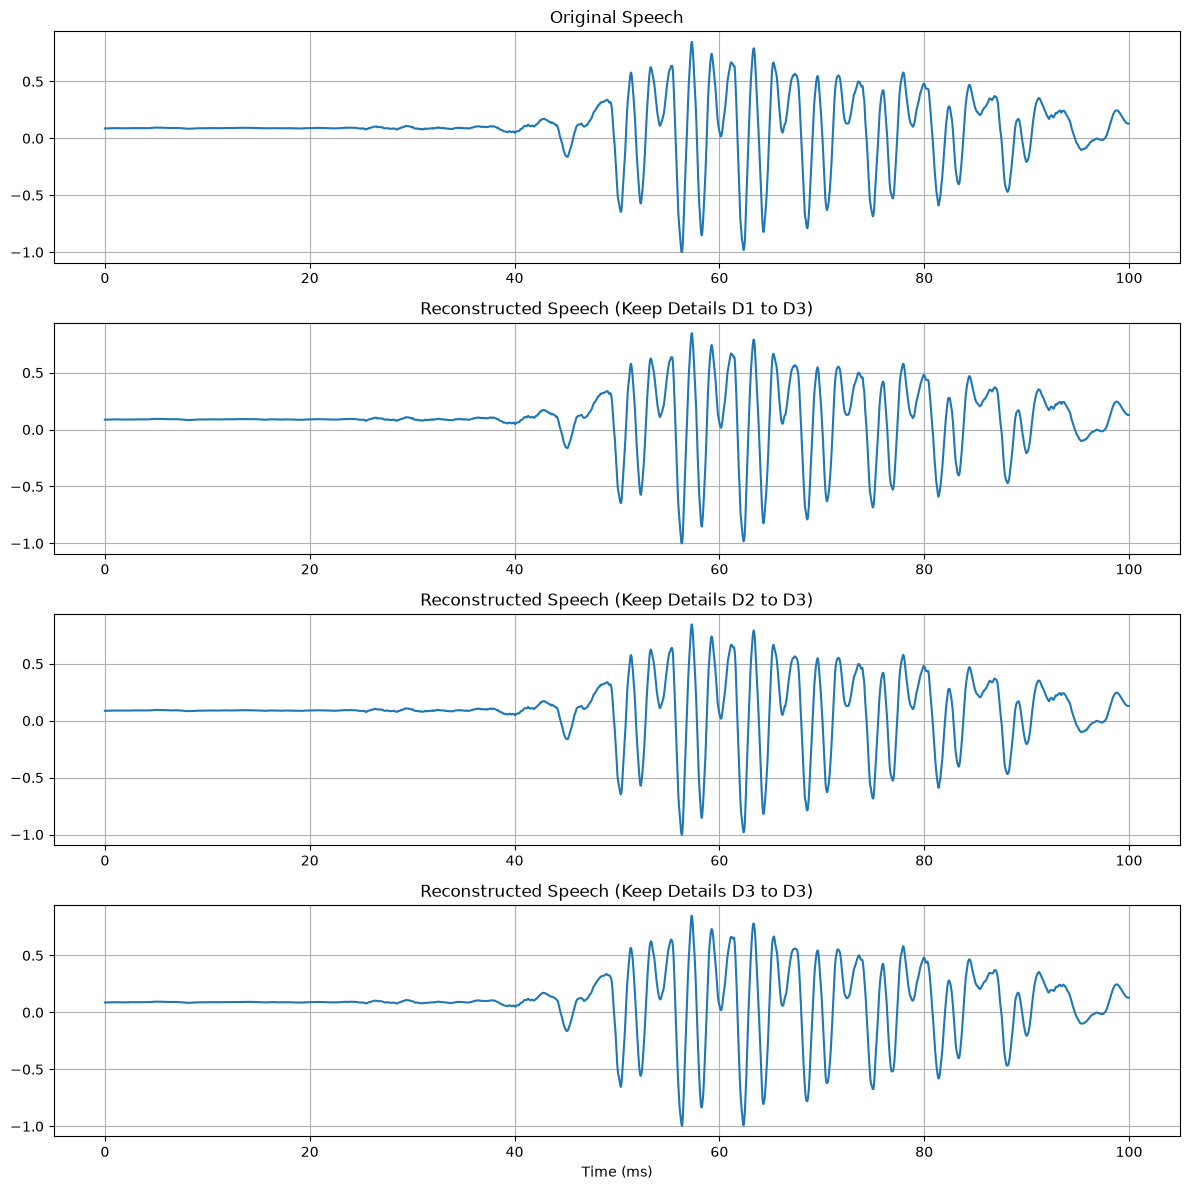

Wavelet analysis completed successfully.
Sampling rate: 44100 Hz
Wavelet: db4
Decomposition level: 3


In [40]:

import numpy as np
import librosa
import pywt
import matplotlib.pyplot as plt

# 1. Load speech signal
audio_path = r"C:\Users\nitud\Downloads\download.wav"

try:
    signal, sr = librosa.load(audio_path, sr=None, mono=True)
except Exception as e:
    print("Audio loading error:", e)
    raise SystemExit

if len(signal) == 0:
    print("Error: Audio file is empty.")
    raise SystemExit

# 2. Select speech segment
start_time = 0.5
duration = 0.1

start = int(start_time * sr)
end = min(start + int(duration * sr), len(signal))
x = signal[start:end]

if len(x) < 32:
    print("Error: Selected segment is too short.")
    raise SystemExit

# Normalize signal
peak = np.max(np.abs(x))
if peak == 0:
    print("Error: Selected segment contains silence.")
    raise SystemExit

x = x / peak
time = np.arange(len(x)) / sr * 1000

# 3. Wavelet decomposition
wavelet = "db4"
max_level = pywt.dwt_max_level(len(x), pywt.Wavelet(wavelet).dec_len)
level = min(3, max_level)

if level < 1:
    print("Error: Signal is too short for wavelet decomposition.")
    raise SystemExit

coeffs = pywt.wavedec(x, wavelet, level=level)

# 4. Plot original speech
plt.figure(figsize=(12, 3))
plt.plot(time, x)
plt.title("Original Speech Signal")
plt.xlabel("Time (ms)")
plt.ylabel("Amplitude")
plt.grid(True)
plt.tight_layout()
plt.show()

# 5. Plot wavelet coefficients
fig, axes = plt.subplots(len(coeffs), 1, figsize=(12, 3 * len(coeffs)))
axes = np.atleast_1d(axes)

for i, c in enumerate(coeffs):
    if i == 0:
        label = f"Approximation A{level}"
    else:
        label = f"Detail D{level - i + 1}"

    axes[i].plot(c)
    axes[i].set_title(label)
    axes[i].set_ylabel("Coefficient")
    axes[i].grid(True)

axes[-1].set_xlabel("Coefficient Index")
plt.tight_layout()
plt.show()

# 6. Reconstruct using approximation + selected detail levels
fig, axes = plt.subplots(level + 1, 1, figsize=(12, 3 * (level + 1)))
axes = np.atleast_1d(axes)

axes[0].plot(time, x)
axes[0].set_title("Original Speech")
axes[0].grid(True)

for keep_level in range(1, level + 1):
    # coeffs = [A_level, D_level, D_(level-1), ..., D1]
    # Keep approximation and details from keep_level upwards
    filtered_coeffs = [c.copy() for c in coeffs]

    for idx in range(level - keep_level + 1, len(filtered_coeffs)):
        filtered_coeffs[idx] = np.zeros_like(filtered_coeffs[idx])

    reconstructed = pywt.waverec(filtered_coeffs, wavelet)
    reconstructed = reconstructed[:len(x)]

    axes[keep_level].plot(time, reconstructed)
    axes[keep_level].set_title(
        f"Reconstructed Speech (Keep Details D{keep_level} to D{level})"
    )
    axes[keep_level].grid(True)

axes[-1].set_xlabel("Time (ms)")
plt.tight_layout()
plt.show()

print("Wavelet analysis completed successfully.")
print("Sampling rate:", sr, "Hz")
print("Wavelet:", wavelet)
print("Decomposition level:", level)


In [43]:
%pip install SpeechRecognition sounddevice scipy

   ---------------------------------------- 0.0/32.9 MB ? eta -:--:--
   ---------------------------------------- 0.3/32.9 MB ? eta -:--:--
    --------------------------------------- 0.5/32.9 MB 1.3 MB/s eta 0:00:25
    --------------------------------------- 0.8/32.9 MB 1.4 MB/s eta 0:00:24
   - -------------------------------------- 1.0/32.9 MB 1.4 MB/s eta 0:00:23
   - -------------------------------------- 1.3/32.9 MB 1.4 MB/s eta 0:00:24
   - -------------------------------------- 1.6/32.9 MB 1.3 MB/s eta 0:00:24
   -- ------------------------------------- 1.8/32.9 MB 1.4 MB/s eta 0:00:23
   -- ------------------------------------- 2.4/32.9 MB 1.5 MB/s eta 0:00:21
   ---- ----------------------------------- 3.4/32.9 MB 1.9 MB/s eta 0:00:16
   ---- ----------------------------------- 3.7/32.9 MB 1.9 MB/s eta 0:00:16
   ----- ---------------------------------- 4.2/32.9 MB 1.9 MB/s eta 0:00:16
   ----- ---------------------------------- 4.5/32.9 MB 1.9 MB/s eta 0:00:16
   ------ ---

In [ ]:
#Write a MATLAB/Python program to recognize speech signal.
import speech_recognition as sr
import sounddevice as sd
from scipy.io.wavfile import write

# Recording settings
fs = 16000
duration = 5
audio_path = r"C:\Users\nitud\Downloads\download.wav"

# Record speech
print("Speak now...")

audio = sd.rec(
    int(duration * fs),
    samplerate=fs,
    channels=1,
    dtype="int16"
)

sd.wait()

# Save recording
write(audio_path, fs, audio)
print("Recording completed.")

# Recognize speech
recognizer = sr.Recognizer()

try:
    with sr.AudioFile(audio_path) as source:
        recorded_audio = recognizer.record(source)

    text = recognizer.recognize_google(
        recorded_audio,
        language="en-US"
    )

    print("Recognized Speech:", text)

except sr.UnknownValueError:
    print("Speech could not be recognized.")

except sr.RequestError as e:
    print("Recognition service error:", e)

except Exception as e:
    print("Error:", e)

Speak now...
Recording completed.
Recognized Speech: hey what's up


In [56]:
%pip install pyttsx3 sounddevice scipy


   ---------------------------------------- 0.0/7.0 MB ? eta -:--:--
   - -------------------------------------- 0.3/7.0 MB ? eta -:--:--
   -- ------------------------------------- 0.5/7.0 MB 1.4 MB/s eta 0:00:05
   ---- ----------------------------------- 0.8/7.0 MB 1.4 MB/s eta 0:00:05
   ------- -------------------------------- 1.3/7.0 MB 1.5 MB/s eta 0:00:04
   -------- ------------------------------- 1.6/7.0 MB 1.4 MB/s eta 0:00:04
   ---------- ----------------------------- 1.8/7.0 MB 1.5 MB/s eta 0:00:04
   ------------- -------------------------- 2.4/7.0 MB 1.6 MB/s eta 0:00:03
   ---------------- ----------------------- 2.9/7.0 MB 1.7 MB/s eta 0:00:03
   ----------------- ---------------------- 3.1/7.0 MB 1.7 MB/s eta 0:00:03
   ------------------- -------------------- 3.4/7.0 MB 1.7 MB/s eta 0:00:03
   ---------------------- ----------------- 3.9/7.0 MB 1.7 MB/s eta 0:00:02
   ------------------------- -------------- 4.5/7.0 MB 1.7 MB/s eta 0:00:02
   -----------------------

In [70]:
%pip install gTTS


  Attempting uninstall: click

    Found existing installation: click 8.5.0

    Uninstalling click-8.5.0:

      Successfully uninstalled click-8.5.0

   ---------------------------------------- 0/2 [click]
   ---------------------------------------- 0/2 [click]
   -------------------- ------------------- 1/2 [gTTS]
   -------------------- ------------------- 1/2 [gTTS]
   -------------------- ------------------- 1/2 [gTTS]
   ---------------------------------------- 2/2 [gTTS]

Note: you may need to restart the kernel to use updated packages.


ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
huggingface-hub 2.1.1 requires click<9.0.0,>=8.4.2, but you have click 8.1.8 which is incompatible.


In [74]:
#Write a MATLAB/Python program for text-to-speech conversion and record speech signal.
from gtts import gTTS
import os

# Input text
text = input("Enter text: ")

try:
    # Convert text to speech
    tts = gTTS(text=text, lang="en")

    # Save speech as MP3
    file_path = os.path.join(
        os.path.expanduser("~"),
        "Downloads",
        "speech.mp3"
    )

    tts.save(file_path)

    print("Text-to-speech conversion completed.")
    print("Speech saved at:", file_path)

    # Play the generated speech
    os.startfile(file_path)

except Exception as e:
    print("Error:", e)

Text-to-speech conversion completed.
Speech saved at: C:\Users\nitud\Downloads\speech.mp3
